# Actividad 17. Benchmark Las Vegas vs. Monte Carlo

**Materia:** Lenguajes de Computación · Otoño 2026

| Nombre completo | No. de cuenta |
|---|---|
| Angel Rugerio Jiménez | 201720 |

**Opción B — Teoría de números / Criptografía:** búsqueda exacta de factores primos (Las Vegas) vs. test de primalidad de Miller-Rabin (Monte Carlo).

**Problema.** Dado un lote de $N$ enteros impares aleatorios de 14 dígitos ($10^{13} \le n < 10^{14}$), decidir cuáles son primos.

| | Las Vegas | Monte Carlo |
|---|---|---|
| Algoritmo | Factorización completa con Pollard $\rho$ (semilla aleatoria) | Miller-Rabin con $k$ bases aleatorias |
| Respuesta | Siempre correcta: devuelve la factorización y se verifica | "Primo" puede ser falso, con probabilidad $\le 4^{-k}$ |
| Tiempo | Variable aleatoria: depende de las semillas que salgan, esperado $O(n^{1/4})$ por número | Acotado y fijo: $k$ exponenciaciones modulares, $O(k \log^3 n)$ por número |

In [1]:
import math
import random
import statistics
import time
import tracemalloc

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

SEMILLA = 2026
random.seed(SEMILLA)

TAMANOS_N = [10**2, 10**3, 10**4, 10**5]  # números por lote
RONDAS_K = [1, 5, 10, 20, 50]             # rondas de Miller-Rabin
K_TABLA = 10                              # k usado en la tabla comparativa
RANGO = (10**13, 10**14)                  # tamaño de los números a probar
REPETICIONES = {10**2: 20, 10**3: 10, 10**4: 5, 10**5: 3}  # corridas por N para el tiempo
ENSAYOS_ERROR = 20_000                    # ensayos por k para la tasa de error

C_LV, C_MC = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3dd", "figure.dpi": 110})

## 1. Monte Carlo: test de Miller-Rabin

Se escribe $n - 1 = 2^s d$ con $d$ impar. Una base $a$ es **testigo** de que $n$ es compuesto si $a^d \not\equiv 1$ y $a^{2^r d} \not\equiv -1 \pmod n$ para todo $0 \le r < s$. Si $n$ es primo, ninguna base es testigo; si $n$ es compuesto, a lo más $\frac{1}{4}$ de las bases no lo son (los **mentirosos fuertes**).

- **Error de un solo lado:** si responde "compuesto" es seguro; solo "primo" puede ser falso.
- **Amplificación del éxito:** con $k$ bases independientes, un compuesto pasa las $k$ rondas con probabilidad $\le 4^{-k}$.

In [2]:
def ronda_miller_rabin(n, a):
    # True si n pasa la ronda con base a (a no es testigo de que n sea compuesto)
    d, s = n - 1, 0
    while d % 2 == 0:
        d //= 2
        s += 1
    x = pow(a, d, n)
    if x == 1 or x == n - 1:
        return True
    for _ in range(s - 1):
        x = x * x % n
        if x == n - 1:
            return True
    return False


def miller_rabin(n, k):
    # Monte Carlo: k rondas con bases aleatorias. Costo fijo; "primo" puede fallar
    if n < 4:
        return n in (2, 3)
    if n % 2 == 0:
        return False
    for _ in range(k):
        if not ronda_miller_rabin(n, random.randrange(2, n - 1)):
            return False  # se encontró un testigo: compuesto con certeza
    return True

## 2. Las Vegas: búsqueda exacta de factores primos

1. **División entre primos pequeños** (< 1000) para quitar los factores fáciles.
2. **Pollard $\rho$:** con $x_0$ y $c$ aleatorios itera $x \mapsto x^2 + c \bmod m$ y busca $\gcd(|x - y|, m) > 1$ (ciclo de Floyd). Si la semilla falla ($\gcd = m$) se vuelve a intentar con otra: **nunca devuelve un factor incorrecto**, solo puede tardar más.
3. **Certificación de cada factor** con Miller-Rabin *determinista*: las bases fijas $\{2, 3, 5, 7, 11, 13, 17\}$ deciden la primalidad sin error para todo $n < 3.4 \times 10^{14}$ (Jaeschke, 1993), así que aquí no hay azar en la respuesta.

El número es primo si y solo si su factorización tiene un solo factor. Lo aleatorio es **cuánto tarda**, no **qué responde**.

In [3]:
PRIMOS_PEQUENOS = [p for p in range(2, 1000) if all(p % q for q in range(2, math.isqrt(p) + 1))]
BASES_DETERMINISTAS = (2, 3, 5, 7, 11, 13, 17)
LIMITE_DETERMINISTA = 341_550_071_728_321  # las bases de arriba son exactas por debajo de este valor


def es_primo_exacto(n):
    # Primalidad sin error para n < LIMITE_DETERMINISTA (bases fijas, sin azar)
    assert n < LIMITE_DETERMINISTA
    if n < 2:
        return False
    for p in BASES_DETERMINISTAS:
        if n % p == 0:
            return n == p
    return all(ronda_miller_rabin(n, a) for a in BASES_DETERMINISTAS)


def pollard_rho(m):
    # Devuelve un divisor propio de m (compuesto e impar). Los reintentos son la fuente de azar
    while True:
        x = random.randrange(2, m)
        c = random.randrange(1, m)
        y, d = x, 1
        while d == 1:
            x = (x * x + c) % m          # tortuga: un paso
            y = (y * y + c) % m          # liebre: dos pasos
            y = (y * y + c) % m
            d = math.gcd(abs(x - y), m)
        if d != m:
            return d                     # éxito; si d == m la semilla falló y se reintenta


def factorizar(n):
    # Las Vegas: factorización completa de n, ordenada. Su producto siempre es n
    factores = []
    for p in PRIMOS_PEQUENOS:
        while n % p == 0:
            factores.append(p)
            n //= p
    pendientes = [n] if n > 1 else []
    while pendientes:
        m = pendientes.pop()
        if es_primo_exacto(m):
            factores.append(m)
        else:
            d = pollard_rho(m)
            pendientes += [d, m // d]
    return sorted(factores)


def es_primo_las_vegas(n):
    return n > 1 and len(factorizar(n)) == 1

## 3. Suite de pruebas

Antes de medir se verifica que cada función hace lo que dice.

In [4]:
def pruebas():
    # Primalidad exacta contra una criba en [0, 10^5)
    criba = [False, False] + [True] * (10**5 - 2)
    for i in range(2, math.isqrt(10**5) + 1):
        if criba[i]:
            criba[i * i::i] = [False] * len(criba[i * i::i])
    assert all(es_primo_exacto(n) == criba[n] for n in range(10**5))
    assert all(es_primo_las_vegas(n) == criba[n] for n in range(2, 10**4))

    # Factorización: producto correcto y todos los factores primos
    casos = [2, 97, 1001, 2**40, 999_983 * 1_000_003, 18_000_041 * 18_000_067, 10**13 + 37, 99_999_999_999_973]
    casos += [random.randrange(*RANGO) for _ in range(300)]
    for n in casos:
        f = factorizar(n)
        assert math.prod(f) == n and all(es_primo_exacto(p) for p in f), n

    # Miller-Rabin nunca rechaza un primo y detecta compuestos comunes
    primos = [n for n in range(3, 10**4) if criba[n]]
    assert all(miller_rabin(p, 5) for p in primos)
    assert not any(miller_rabin(n, 20) for n in range(9, 10**4, 2) if not criba[n])

    # Ambos algoritmos coinciden en números de 14 dígitos
    for n in casos[8:]:
        assert miller_rabin(n, 20) == es_primo_las_vegas(n)
    print("✔ Todas las pruebas pasaron")


pruebas()

✔ Todas las pruebas pasaron


## 4. Benchmark de tiempo, memoria y error

- **Tiempo:** `time.perf_counter()` en milisegundos, para todo el lote de $N$ números. Cada repetición usa un lote nuevo.
- **Memoria:** pico de memoria con `tracemalloc`, en una corrida aparte para no contaminar los tiempos.
- **Error:** se compara cada respuesta de Monte Carlo con la de Las Vegas, que es la verdad.

In [5]:
def generar_lote(n_numeros):
    return [random.randrange(RANGO[0], RANGO[1]) | 1 for _ in range(n_numeros)]  # impares


def medir_ms(funcion, lote):
    t0 = time.perf_counter()
    respuestas = [funcion(n) for n in lote]
    return (time.perf_counter() - t0) * 1000, respuestas


def memoria_pico_kib(funcion, lote):
    # Solo la memoria de trabajo del algoritmo: las respuestas no se guardan
    tracemalloc.start()
    for n in lote:
        funcion(n)
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return pico / 1024


mc_k = lambda k: (lambda n: miller_rabin(n, k))
filas_tiempo, filas_tabla = [], []
for N in TAMANOS_N:
    t_lv, t_mc, t_mc50, fallos, primos = [], [], [], 0, 0
    for _ in range(REPETICIONES[N]):
        lote = generar_lote(N)
        t, verdad = medir_ms(es_primo_las_vegas, lote)
        t_lv.append(t)
        t, resp = medir_ms(mc_k(K_TABLA), lote)
        t_mc.append(t)
        t_mc50.append(medir_ms(mc_k(50), lote)[0])
        fallos += sum(r != v for r, v in zip(resp, verdad))
        primos += sum(verdad)
    for metodo, ts in (("Las Vegas", t_lv), (f"Monte Carlo k={K_TABLA}", t_mc), ("Monte Carlo k=50", t_mc50)):
        filas_tiempo += [{"método": metodo, "N": N, "ms": t} for t in ts]

    lote = generar_lote(N)
    total = N * REPETICIONES[N]
    filas_tabla.append({
        "N": N,
        "primos en el lote (%)": 100 * primos / total,
        "LV tiempo medio (ms)": statistics.mean(t_lv),
        "LV desv. est. (ms)": statistics.stdev(t_lv),
        "LV memoria pico (KiB)": memoria_pico_kib(es_primo_las_vegas, lote),
        "LV error (%)": 0.0,
        f"MC k={K_TABLA} tiempo medio (ms)": statistics.mean(t_mc),
        f"MC k={K_TABLA} desv. est. (ms)": statistics.stdev(t_mc),
        f"MC k={K_TABLA} memoria pico (KiB)": memoria_pico_kib(mc_k(K_TABLA), lote),
        f"MC k={K_TABLA} error (%)": 100 * fallos / total,
        "Aceleración LV / MC": statistics.mean(t_lv) / statistics.mean(t_mc),
    })
    print(f"N = {N:>7,}: {REPETICIONES[N]} repeticiones listas")

df_tiempo = pd.DataFrame(filas_tiempo)
df_tabla = pd.DataFrame(filas_tabla).set_index("N")

N =     100: 20 repeticiones listas


N =   1,000: 10 repeticiones listas


N =  10,000: 5 repeticiones listas


N = 100,000: 3 repeticiones listas


### Tasa de error de Monte Carlo según $k$

Con números aleatorios Miller-Rabin prácticamente nunca se equivoca: casi todos los compuestos tienen muy pocos mentirosos fuertes, así que la tasa de error del lote aleatorio sale en 0 % y no deja ver la amplificación. Para medirla se usa el **peor caso**: compuestos $n = (2x+1)(4x+1)$ con ambos factores primos, cuya fracción de mentirosos se acerca a la cota de $\frac{1}{4}$.

Para cada uno se cuenta la fracción exacta de mentirosos $\ell_n$ (probando todas las bases), de modo que la probabilidad teórica de error con $k$ rondas es $\ell_n^{\,k}$. Cada ensayo elige uno de esos compuestos al azar y corre Miller-Rabin con $k$ rondas; es un error si responde "primo".

In [6]:
def fraccion_mentirosos(n):
    # Fracción exacta de bases a en [2, n-2] que no detectan que n es compuesto
    return sum(ronda_miller_rabin(n, a) for a in range(2, n - 1)) / (n - 3)


ADVERSARIOS = {}
for x in range(1, 200):
    p, q = 2 * x + 1, 4 * x + 1
    if es_primo_exacto(p) and es_primo_exacto(q) and p * q < 200_000:
        ADVERSARIOS[p * q] = fraccion_mentirosos(p * q)
ADVERSARIOS = {n: l for n, l in ADVERSARIOS.items() if l > 0.2}  # los más difíciles
display(Markdown("| Compuesto $n$ | Factores | Mentirosos fuertes |\n|---|---|---|\n" + "\n".join(
    f"| {n:,} | {' × '.join(map(str, factorizar(n)))} | {100 * l:.2f} % |" for n, l in ADVERSARIOS.items())))

lista_adv = list(ADVERSARIOS)
filas_error = []
for k in RONDAS_K:
    fallos = sum(miller_rabin(random.choice(lista_adv), k) for _ in range(ENSAYOS_ERROR))
    filas_error.append({
        "k": k,
        "error empírico (%)": 100 * fallos / ENSAYOS_ERROR,
        "error teórico (%)": 100 * statistics.mean(l**k for l in ADVERSARIOS.values()),
        "cota 4^-k (%)": 100 * 4.0**-k,
        "fallos observados": fallos,
    })
df_error = pd.DataFrame(filas_error).set_index("k")

| Compuesto $n$ | Factores | Mentirosos fuertes |
|---|---|---|
| 703 | 19 × 37 | 22.86 % |
| 1,891 | 31 × 61 | 23.73 % |
| 12,403 | 79 × 157 | 24.52 % |
| 38,503 | 139 × 277 | 24.73 % |
| 79,003 | 199 × 397 | 24.81 % |
| 88,831 | 211 × 421 | 24.82 % |
| 146,611 | 271 × 541 | 24.86 % |
| 188,191 | 307 × 613 | 24.88 % |

## 5. Tablas comparativas

In [7]:
fmt = lambda x: f"{x:,.3f}" if isinstance(x, float) else x
display(Markdown(df_tabla.T.map(fmt).to_markdown()))
df_tabla.to_csv("tabla_comparativa.csv")

|                            |    100 |   1000 |   10000 |   100000 |
|:---------------------------|-------:|-------:|--------:|---------:|
| primos en el lote (%)      |  6.1   |  6.19  |   6.39  |    6.331 |
| LV tiempo medio (ms)       | 10.625 | 85.444 | 821.861 | 9477.45  |
| LV desv. est. (ms)         |  2.825 |  8.904 |  13.876 |  617.407 |
| LV memoria pico (KiB)      |  0.93  |  0.992 |   2.066 |    2.434 |
| LV error (%)               |  0     |  0     |   0     |    0     |
| MC k=10 tiempo medio (ms)  |  1.03  |  7.054 |  73.639 |  933.566 |
| MC k=10 desv. est. (ms)    |  0.241 |  0.996 |   5.878 |  111.268 |
| MC k=10 memoria pico (KiB) |  0.242 |  0.242 |   0.277 |    1.324 |
| MC k=10 error (%)          |  0     |  0     |   0     |    0     |
| Aceleración LV / MC        | 10.315 | 12.112 |  11.161 |   10.152 |

In [8]:
display(Markdown(df_error.map(lambda x: f"{x:.3g}" if isinstance(x, float) else x).to_markdown()))
df_error.to_csv("tabla_error_vs_k.csv")

|   k |   error empírico (%) |   error teórico (%) |   cota 4^-k (%) |   fallos observados |
|----:|---------------------:|--------------------:|----------------:|--------------------:|
|   1 |                24.3  |           24.4      |       25        |                4860 |
|   5 |                 0.12 |            0.0871   |        0.0977   |                  24 |
|  10 |                 0    |            7.72e-05 |        9.54e-05 |                   0 |
|  20 |                 0    |            6.28e-11 |        9.09e-11 |                   0 |
|  50 |                 0    |            3.9e-29  |        7.89e-29 |                   0 |

## 6. Gráficas

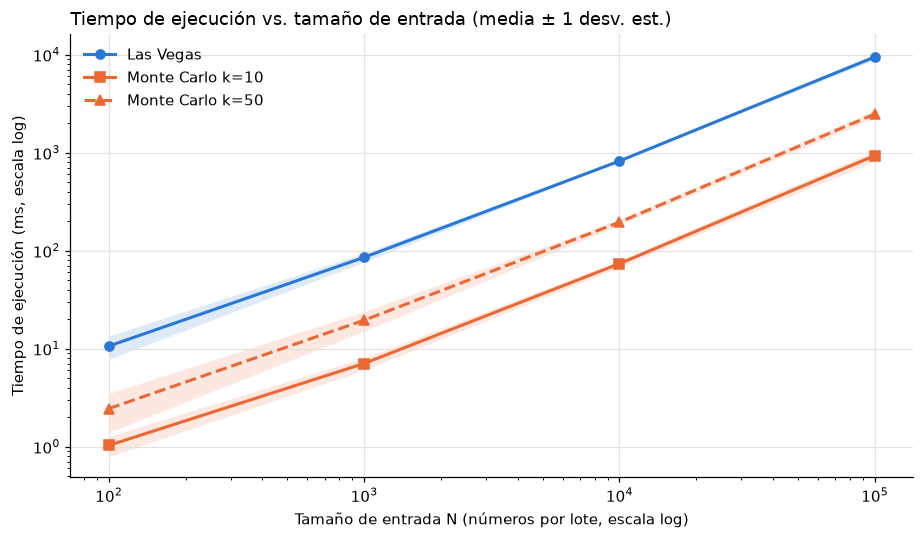

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 5))
for metodo, color, marca, estilo in (("Las Vegas", C_LV, "o", "-"),
                                     (f"Monte Carlo k={K_TABLA}", C_MC, "s", "-"),
                                     ("Monte Carlo k=50", C_MC, "^", "--")):
    g = df_tiempo[df_tiempo["método"] == metodo].groupby("N")["ms"]
    media, de = g.mean(), g.std()
    ax.fill_between(media.index, media - de, media + de, color=color, alpha=0.15, lw=0)
    ax.plot(media.index, media, color=color, marker=marca, ls=estilo, lw=2, label=metodo)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Tamaño de entrada N (números por lote, escala log)")
ax.set_ylabel("Tiempo de ejecución (ms, escala log)")
ax.set_title("Tiempo de ejecución vs. tamaño de entrada (media ± 1 desv. est.)", loc="left")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("grafica_tiempo_vs_N.png", dpi=150)
plt.show()

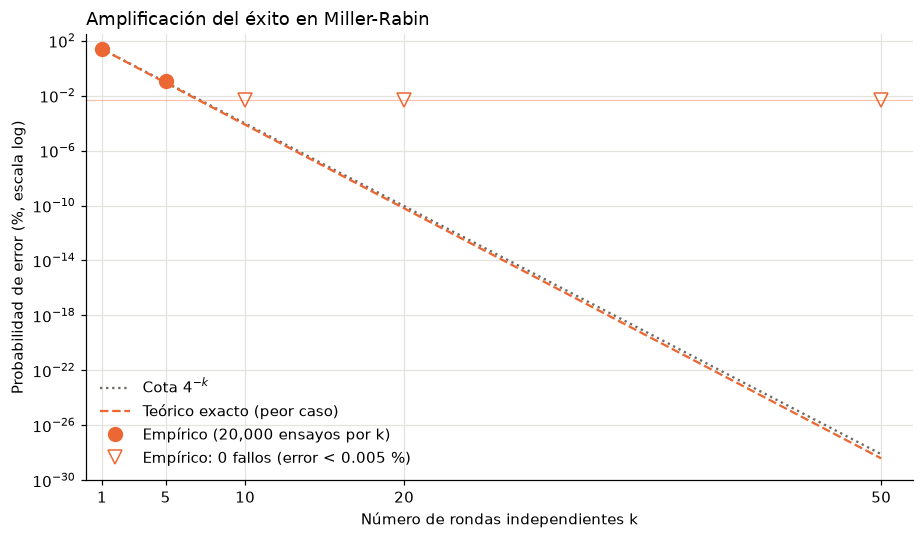

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 5))
kk = range(1, 51)
ax.plot(kk, [100 * 4.0**-k for k in kk], color="#6b6a64", ls=":", lw=1.5, label="Cota $4^{-k}$")
ax.plot(kk, [100 * statistics.mean(l**k for l in ADVERSARIOS.values()) for k in kk],
        color=C_MC, ls="--", lw=1.5, label="Teórico exacto (peor caso)")
hay = df_error[df_error["fallos observados"] > 0]
cero = df_error[df_error["fallos observados"] == 0]
ax.plot(hay.index, hay["error empírico (%)"], color=C_MC, marker="o", ms=9, lw=0,
        label=f"Empírico ({ENSAYOS_ERROR:,} ensayos por k)")
limite = 100 / ENSAYOS_ERROR  # el menor error distinto de 0 que se puede observar
ax.plot(cero.index, [limite] * len(cero), color=C_MC, marker="v", ms=9, lw=0, mfc="white",
        label=f"Empírico: 0 fallos (error < {limite:.3f} %)")
ax.axhline(limite, color=C_MC, lw=0.8, alpha=0.4)
ax.set_yscale("log")
ax.set_ylim(1e-30, 300)
ax.set_xlim(0, 52)
ax.set_xticks(RONDAS_K)
ax.set_xlabel("Número de rondas independientes k")
ax.set_ylabel("Probabilidad de error (%, escala log)")
ax.set_title("Amplificación del éxito en Miller-Rabin", loc="left")
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig("grafica_error_vs_k.png", dpi=150)
plt.show()

### El tiempo de Las Vegas como variable aleatoria

La entrada es **fija** — el semiprimo $18\,000\,041 \times 18\,000\,067 \approx 3.2 \times 10^{14}$, el caso más difícil para Pollard $\rho$ porque sus dos factores son del mismo tamaño — y aun así el tiempo cambia en cada corrida, porque cambian las semillas. La respuesta, en cambio, es siempre la misma.

Respuestas distintas en 500 corridas: {(18000041, 18000067)}
Tiempo (ms): media 1.98, desv. est. 1.12, mín 0.11, máx 6.65


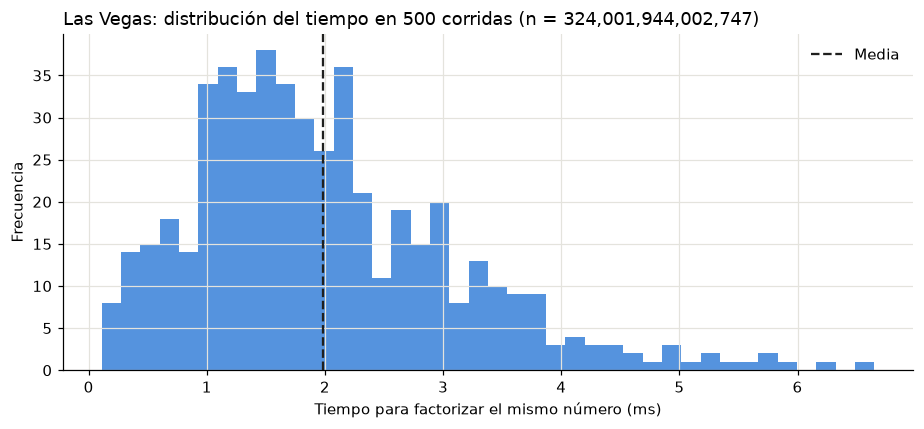

In [11]:
SEMIPRIMO = 18_000_041 * 18_000_067
tiempos, respuestas = [], set()
for _ in range(500):
    t0 = time.perf_counter()
    respuestas.add(tuple(factorizar(SEMIPRIMO)))
    tiempos.append((time.perf_counter() - t0) * 1000)
print(f"Respuestas distintas en 500 corridas: {respuestas}")
print(f"Tiempo (ms): media {statistics.mean(tiempos):.2f}, desv. est. {statistics.stdev(tiempos):.2f}, "
      f"mín {min(tiempos):.2f}, máx {max(tiempos):.2f}")

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.hist(tiempos, bins=40, color=C_LV, alpha=0.8)
ax.axvline(statistics.mean(tiempos), color="#1f1f1e", ls="--", lw=1.5, label="Media")
ax.set_xlabel("Tiempo para factorizar el mismo número (ms)")
ax.set_ylabel("Frecuencia")
ax.set_title(f"Las Vegas: distribución del tiempo en 500 corridas (n = {SEMIPRIMO:,})", loc="left")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("grafica_variabilidad_las_vegas.png", dpi=150)
plt.show()

## 7. Conclusión analítica

**Lo que muestran los datos.** Las Vegas nunca se equivocó: su respuesta es una factorización que se puede comprobar multiplicando. Pero cuesta unas **10 veces más** que Miller-Rabin con $k = 10$ en todos los tamaños (≈9 s contra menos de 1 s con $N = 10^5$). Las dos curvas son rectas paralelas porque el costo **por número** no depende de $N$, sino del tamaño de cada número: Pollard $\rho$ necesita del orden de $n^{1/4}$ iteraciones (unas $10^3$–$10^4$ para 14 dígitos), mientras que Miller-Rabin hace $k$ exponenciaciones modulares de $O(\log^3 n)$. Con números de 14 dígitos la diferencia es "solo" de 10×; con los números de 600 dígitos de RSA, Miller-Rabin sigue tardando milisegundos y factorizar es inviable. La memoria de trabajo es pequeña en ambos (unos cuantos KiB), un poco mayor en Las Vegas por la lista de factores pendientes.

**El tiempo de Las Vegas es una variable aleatoria.** Al factorizar 500 veces el mismo número la respuesta fue siempre la misma, pero el tiempo fue de ≈0.1 ms hasta varios milisegundos (el máximo, varias veces la media), con desviación estándar de más de la mitad de la media. Solo se garantiza el tiempo **esperado**, no el de cada corrida.

**Amplificación del éxito.** Con números aleatorios Miller-Rabin no falló ni una vez en los ≈362,000 números del benchmark, porque los compuestos típicos casi no tienen mentirosos fuertes. En el peor caso ($n = (2x+1)(4x+1)$, ≈25 % de mentirosos) una sola ronda falló el 24.3 % de las veces, igual a la predicción teórica. Con $k = 5$ bajó a ≈0.1 %, y con $k \ge 10$ no se observó ningún fallo en 20,000 ensayos, como se esperaba: la probabilidad teórica es $< 10^{-6}$ con $k = 10$ y $< 10^{-28}$ con $k = 50$. Cada ronda multiplica el error por ≈$\frac14$ y solo suma un costo constante: el error cae exponencialmente mientras el tiempo crece linealmente (k = 50 tarda ≈2.5 veces lo que k = 10).

**¿Cuándo conviene sacrificar la certeza por velocidad?**

- **Generación de llaves criptográficas (RSA, Diffie-Hellman).** Hay que encontrar primos de cientos de dígitos: se prueban candidatos al azar con Miller-Rabin hasta que uno pasa. Factorizar para tener certeza es imposible, y con 40–64 rondas la probabilidad de aceptar un compuesto es menor que la de un error del hardware. Bibliotecas como OpenSSL lo hacen así.
- **Cuando el error se puede hacer tan pequeño como se quiera.** Si cada ronda reduce el error por un factor constante, se elige $k$ según el riesgo aceptable y el costo sigue siendo predecible.
- **Cuando hay un límite de tiempo estricto.** Monte Carlo tarda siempre lo mismo; Las Vegas puede tener corridas varias veces más lentas que el promedio, lo que es un problema en un servidor que debe responder en un plazo fijo.
- **Cuando el error es de un solo lado y se puede verificar después.** Un "compuesto" de Miller-Rabin es seguro; solo el "primo" tiene riesgo, y en muchos sistemas una falla se detectaría en una etapa posterior.

**Cuándo NO conviene.** Si el resultado tiene que ser exacto y demostrable (una prueba matemática, un certificado de primalidad, una auditoría) o si se necesitan los factores y no solo el sí o no, se usa el algoritmo exacto. Con números pequeños, como los de esta actividad, el costo extra de la certeza es de 10×, que puede ser aceptable.

**En resumen:** Las Vegas fija la **calidad** de la respuesta y deja variable el **tiempo**; Monte Carlo fija el **tiempo** y deja variable la **calidad**, pero la controla con $k$. Se elige según cuál de los dos es más caro en la aplicación.